In [2]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import sklearn as sk
df = pd.read_csv("../data/AmesHousing.csv", sep = '\t')



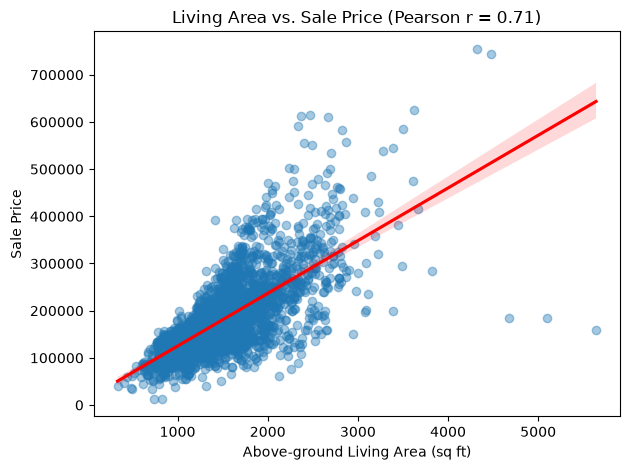

In [4]:
plot_data = df[["Gr Liv Area", "SalePrice"]].dropna()
r = plot_data["Gr Liv Area"].corr(plot_data["SalePrice"])

sns.regplot(
    data=plot_data,
    x="Gr Liv Area",
    y="SalePrice",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.xlabel("Above-ground Living Area (sq ft)")
plt.ylabel("Sale Price")
plt.title(f"Living Area vs. Sale Price (Pearson r = {r:.2f})")
plt.tight_layout()
plt.show()

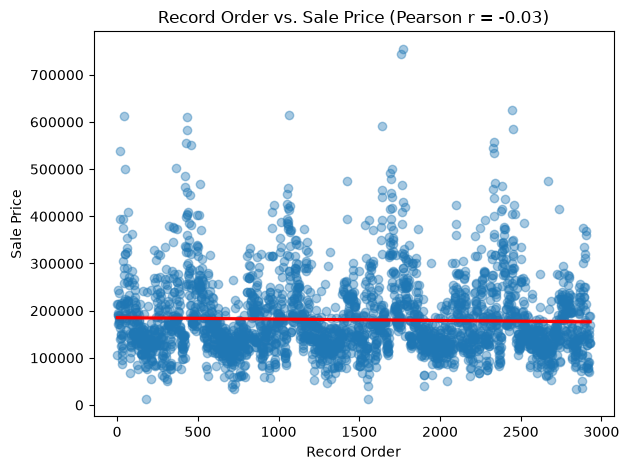

In [6]:
plot_data = df[["Order", "SalePrice"]].dropna()
r = plot_data["Order"].corr(plot_data["SalePrice"])

sns.regplot(
    data=plot_data,
    x="Order",
    y="SalePrice",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.xlabel("Record Order")
plt.ylabel("Sale Price")
plt.title(f"Record Order vs. Sale Price (Pearson r = {r:.2f})")
plt.tight_layout()
plt.show()

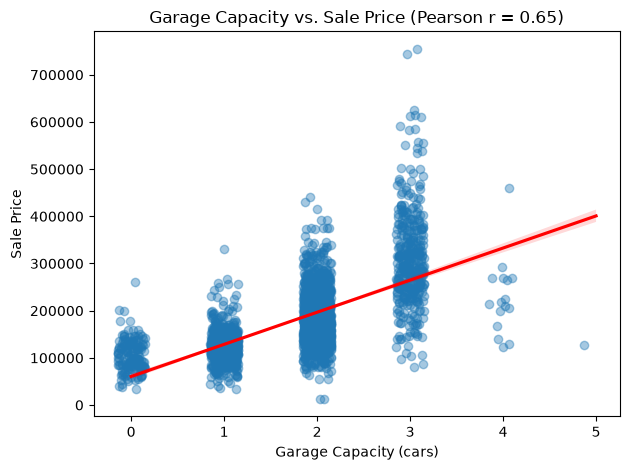

In [8]:
plot_data = df[["Garage Cars", "SalePrice"]].dropna()
r = plot_data["Garage Cars"].corr(plot_data["SalePrice"])

sns.regplot(
    data=plot_data,
    x="Garage Cars",
    y="SalePrice",
    x_jitter=0.15,  # Garage Cars has only a few integer values
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"}
)

plt.xlabel("Garage Capacity (cars)")
plt.ylabel("Sale Price")
plt.title(f"Garage Capacity vs. Sale Price (Pearson r = {r:.2f})")
plt.tight_layout()
plt.show()

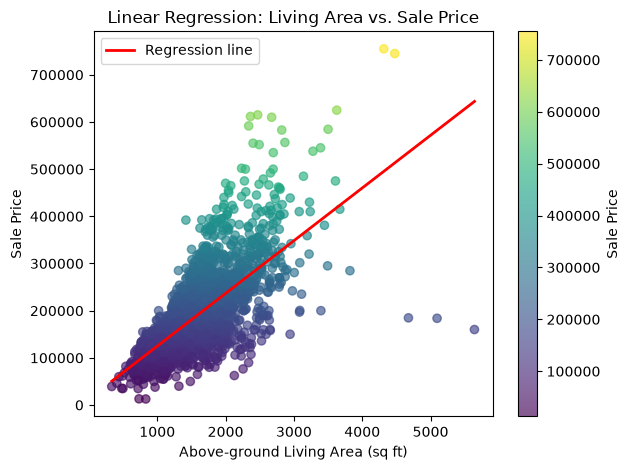

In [10]:
from sklearn.linear_model import LinearRegression
import numpy as np

plot_data = df[["Gr Liv Area", "SalePrice"]].dropna()
X = plot_data[["Gr Liv Area"]]
y = plot_data["SalePrice"]

model = LinearRegression()
model.fit(X, y)

# Sort the x-values so the regression line is drawn smoothly
x_line = np.linspace(X["Gr Liv Area"].min(), X["Gr Liv Area"].max(), 100)
y_line = model.predict(pd.DataFrame({"Gr Liv Area": x_line}))

scatter = plt.scatter(
    X["Gr Liv Area"],
    y,
    c=y,
    cmap="viridis",
    alpha=0.65
)
plt.plot(x_line, y_line, color="red", linewidth=2, label="Regression line")
plt.colorbar(scatter, label="Sale Price")

plt.xlabel("Above-ground Living Area (sq ft)")
plt.ylabel("Sale Price")
plt.title("Linear Regression: Living Area vs. Sale Price")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Compare actual and predicted prices for three real homes:
# small, medium, and large relative to this dataset
areas = plot_data["Gr Liv Area"]
targets = areas.quantile([0.1, 0.5, 0.9])

example_indices = [
    (areas - target).abs().idxmin()
    for target in targets
]

actual_examples = plot_data.loc[example_indices].copy()
actual_examples["Predicted SalePrice"] = model.predict(
    actual_examples[["Gr Liv Area"]]
)
actual_examples["Error (Actual - Predicted)"] = (
    actual_examples["SalePrice"] - actual_examples["Predicted SalePrice"]
)

display(actual_examples.round(0))


# Predict prices for representative living areas.
# These are example sizes, not additional homes from the dataset.
example_areas = (
    areas.quantile([0.25, 0.5, 0.75])
    .round()
    .astype(int)
    .to_numpy()
)

meaningful_points = pd.DataFrame({"Gr Liv Area": example_areas})
meaningful_points["Predicted SalePrice"] = model.predict(meaningful_points)

display(meaningful_points.round(0))

,Gr Liv Area,SalePrice,Predicted SalePrice,Error (Actual - Predicted)
283,924,80000,116495.0,-36495.0
364,1442,180500,174352.0,6148.0
1702,2152,260116,253655.0,6461.0


,Gr Liv Area,Predicted SalePrice
0,1126,139057.0
1,1442,174352.0
2,1743,207972.0
